<div style="border: 3px solid #0d3b0d; border-radius: 10px; overflow: hidden; margin-bottom: 20px; font-family: Arial, sans-serif;">

  <!-- Banner Institucional -->
  <div style="background-color: #006633; padding: 0;">
    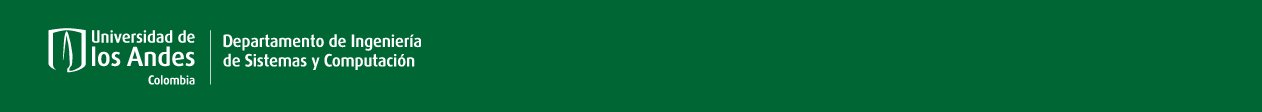
  </div>

  <!-- Titulo del laboratorio -->
  <div style="background-color: #ffffff; padding: 15px 20px; text-align: center;">
    <h2 style="margin: 0; color: #1a1a1a; font-size: 18px;">AI Security - Laboratorio 6 · Sesión 14</h2>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 13px;">Defensa Mediante Entrenamiento Adversarial y Robustecimiento de Modelos</p>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 12px;">Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI)</p>
  </div>

  <!-- Aviso de propiedad intelectual -->
  <div style="background-color: #f5f5f0; padding: 12px 20px; border-top: 1px solid #ddd; font-size: 11px; color: #444; line-height: 1.5;">
    <strong>Propiedad Intelectual - Universidad de los Andes</strong><br>
    Este material es propiedad exclusiva de la Universidad de los Andes (Bogot&aacute;, Colombia) y ha sido desarrollado para el programa de Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI), Departamento de Ingenier&iacute;a de Sistemas y Computaci&oacute;n. Todos los derechos reservados &copy; 2026.<br><br>
    <strong>Condiciones de uso:</strong> Este material se distribuye exclusivamente a los estudiantes matriculados en el curso AI Security del programa MESI y est&aacute; protegido por las leyes colombianas de derechos de autor (Ley 23 de 1982 y Ley 1915 de 2018) y por las disposiciones aplicables de propiedad intelectual de la Universidad de los Andes. Queda estrictamente prohibida su reproducci&oacute;n, distribuci&oacute;n, modificaci&oacute;n, publicaci&oacute;n o transmisi&oacute;n total o parcial, en cualquier forma o medio, sin la autorizaci&oacute;n previa y por escrito de la Universidad de los Andes. El incumplimiento de estas condiciones podr&aacute; dar lugar a las acciones disciplinarias, civiles y penales correspondientes.
  </div>

</div>

# **Laboratorio 6 · Sesión 14: Defensa Mediante Entrenamiento Adversarial y Robustecimiento de Modelos**

**Curso:** AI Security - MESI    


## **Objetivos de Aprendizaje**

Al completar este laboratorio, el estudiante será capaz de:

1. Comprender las estrategias de defensa contra ataques adversariales en modelos de Deep Learning
2. Implementar entrenamiento adversarial (Adversarial Training) utilizando PGD cómo mecanismo de robustecimiento
3. Aplicar destilación defensiva (Defensive Distillation) cómo técnica complementaria de defensa
4. Implementar preprocesamiento de entradas (Feature Squeezing) cómo defensa sin re-entrenamiento
5. Evaluar cuantitativamente el trade-off entre precisión en datos limpios y robustez adversarial
6. Comparar sistematicamente la efectividad de multiples estrategias de defensa

---

## **Aviso Legal y Uso de Datos**

### **Propósito Académico**

Este laboratorio se desarrolla exclusivamente con **fines académicos y educativos** en el marco del curso de AI Security de la Maestría en Seguridad de la Información (MESI) de la Universidad de los Andes. El contenido, técnicas y herramientas presentadas están diseñadas para la enseñanza de conceptos de Machine Learning aplicados a ciberseguridad.

### **Datos Utilizados**

Todos los datasets empleados en este laboratorio son de **uso libre y público**:

- **CIFAR-10:** Dataset de referencia para clasificación de imágenes
  - Fuente: Canadian Institute For Advanced Research
  - Licencia: Uso libre para investigación y educación
  - Contenido: 60,000 imágenes de 32x32 pixeles en 10 clases

### **Limitaciones y Responsabilidad**

- Los modelos y defensas desarrollados en este laboratorio son para **propósitos educativos** únicamente
- No deben ser desplegados en entornos de producción sin validación y pruebas exhaustivas adicionales
- El uso indebido de las técnicas aqui presentadas es responsabilidad exclusiva del usuario
- Este material se rige por las políticas académicas de la Universidad de los Andes

---

## **Metodología: Ciclo CRISP-DM**

Este laboratorio sigue la métodología **CRISP-DM (Cross-Industry Standard Process for Data Mining)**, el estándar de la industria para proyectos de Machine Learning:

1. **Comprensión del Negocio (Business Understanding):** Entender la necesidad de defender modelos de IA contra ataques adversariales
2. **Comprensión de los Datos (Data Understanding):** Explorar CIFAR-10 y los efectos de perturbaciónes adversariales
3. **Preparación de los Datos (Data Preparation):** Generación de ejemplos adversariales para entrenamiento robusto
4. **Modelado (Modeling):** Implementación de defensas: Adversarial Training, Destilación Defensiva y Feature Squeezing
5. **Evaluación (Evaluation):** Comparación sistematica de robustez bajo multiples ataques
6. **Despliegue (Deployment):** Consideraciones para implementación de defensas en producción

A medida que avance en el laboratorio, identifique en que fase de CRISP-DM se encuentra en cada sección.

## **Contexto: ¿Por qué Defender Modelos de IA?**

En el Laboratorio 4 exploramos cómo los ataques adversariales (FGSM, BIM, PGD) pueden engañar a clasificadores de Deep Learning con perturbaciones imperceptibles. En escenarios reales de ciberseguridad, esto representa una amenaza crítica:

- **Evasión de malware:** Un atacante puede modificar ligeramente un binario malicioso para evadir un clasificador basado en CNN.
- **Evasión de NIDS:** Perturbaciones en el tráfico de red pueden burlar sistemas de detección de intrusiones.
- **Ataques a sistemas autónomos:** Modificaciones imperceptibles en señales de tránsito pueden causar accidentes.

### **Estrategias de Defensa**

Las defensas contra ataques adversariales se clasifican en tres grandes categorias:

1. **Modificación del entrenamiento:** Entrenamiento adversarial (PGD-AT), TRADES.
2. **Modificación de la arquitectura/modelo:** Destilación defensiva, suavizado de la superficie de decisión.
3. **Preprocesamiento de entradas:** Feature Squeezing, reducción de profundidad de bits, suavizado espacial.

### **Nuestro objetivo:**
Implementar y comparar estas tres estrategias de defensa, evaluando cuantitativamente su efectividad y el trade-off entre precisión limpia y robustez adversarial.

---

## **1. Configuración del Entorno**

Instalamos las librerias necesarias para este laboratorio.

In [ ]:
import os
import sys

# Agrega la ruta de ejecutables y paquetes locales al PATH y sys.path del sistema
local_bin = os.path.expanduser("~/.local/bin")
if local_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{local_bin}:{os.environ['PATH']}"

user_site = os.path.expanduser("~/.local/lib/python3.10/site-packages")
if user_site not in sys.path:
    sys.path.append(user_site)

In [ ]:
%pip install -q adversarial-robustness-toolbox tensorflow numpy matplotlib scikit-learn scipy

Importaciones

In [ ]:
# TODO: Importa las librerías que usarás en el resto del laboratorio (manejo de datos, visualización, TensorFlow/Keras, ART y métricas).
#
# Orientación general:
# - Revisa las secciones siguientes del notebook para identificar qué se usa: el dataset CIFAR-10 de Keras, las capas y modelos para construir la CNN (secuencial y funcional), el optimizador, la función de pérdida, la codificación one-hot y los callbacks de entrenamiento.
# - De ART necesitarás el wrapper de clasificadores para TensorFlow v2 y las clases de los ataques de evasión que se evalúan (FGSM, PGD, Carlini & Wagner L2 y Square Attack). Revisa también qué ofrece ART en sus módulos de defensas.
# - Para el feature squeezing necesitarás un filtro de mediana (por ejemplo, el de scipy.ndimage).
# - Si hay una GPU disponible, habilita el crecimiento de memoria dinámico para evitar que TensorFlow reserve toda la memoria del dispositivo de una vez.
# - Configura el manejo de warnings, fija una semilla aleatoria (RANDOM_STATE) para que los resultados sean reproducibles, e imprime la versión de TensorFlow y si hay GPU disponible.

# TODO: Desarrollar la solución de esta sección.
pass

### **Documentación de Librerias:**
Si no esta familiarizado con alguna libreria, consulte:
- [ART - Adversarial Robustness Toolbox](https://adversarial-robustness-toolbox.readthedocs.io/) - Documentación oficial
- [TensorFlow/Keras - Guia oficial](https://www.tensorflow.org/guide)
- [Matplotlib - Galería de ejemplos](https://matplotlib.org/stable/gallery/index.html)

---

## **2. Comprensión y Preparación de los Datos**

Utilizaremos el dataset **CIFAR-10** como benchmark. Este dataset es el estándar en la literatura de robustez adversarial (Madry et al., 2018; Zhang et al., 2019) lo que permite a los estudiantes contrastar directamente sus resultados con los reportados en publicaciones académicas.

**Justificación del dataset:** A diferencia del modelo Malimg usado en laboratorios anteriores (25 familias, imágenes de mayor resolución), CIFAR-10 ofrece imágenes de 32x32 pixeles con 10 clases. Esto permite que los ciclos de entrenamiento adversarial (que requieren generar perturbaciónes en cada epoca) sean computacionalmente viables.

In [ ]:
# Carga del dataset CIFAR-10
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = cifar10.load_data()

# Nombres de las clases
CIFAR10_CLASSES = [
    'avion', 'automovil', 'pajaro', 'gato', 'ciervo',
    'perro', 'rana', 'caballo', 'barco', 'camion'
]

print(f"Datos de entrenamiento: {x_train_raw.shape}")
print(f"Datos de prueba: {x_test_raw.shape}")
print(f"Rango de valores original: [{x_train_raw.min()}, {x_train_raw.max()}]")
print(f"Clases: {len(CIFAR10_CLASSES)}")

### **2.1 Preprocesamiento**

Normalizamos las imágenes al rango [0, 1], que es el rango estándar para trabajar con la libreria ART y con los ataques adversariales basados en gradientes.

In [ ]:
# Normalización al rango [0, 1]
x_train = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0

# One-hot encoding de las etiquetas
y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

print(f"Rango de valores normalizado: [{x_train.min()}, {x_train.max()}]")
print(f"Forma de etiquetas (one-hot): {y_train.shape}")

### **2.2 Visualización exploratoria**

Visualicemos algunas muestras del dataset para entender los datos con los que trabajaremos.

In [ ]:
# Visualización de muestras por clase
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Muestras de CIFAR-10 por Clase', fontsize=14, fontweight='bold')

for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_raw.flatten() == i)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(CIFAR10_CLASSES[i], fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

# Distribución de clases
unique, counts = np.unique(y_train_raw, return_counts=True)
print("Distribución de clases en entrenamiento:")
for cls, cnt in zip(CIFAR10_CLASSES, counts):
    print(f"  {cls}: {cnt} muestras")

---

## **3. Construcción del Modelo Base (Línea Base)**

Construiremos una CNN desde cero que servira cómo nuestro **modelo base sin defensas**. Este modelo sera la referencia contra la cual mediremos la mejora de cada estrategia de defensa.

La arquitectura sigue un patrón estándar de CNN con bloques convolucionales progresivos, BatchNormalization para estabilidad del entrenamiento, y Dropout para regularización.

In [ ]:
def build_cifar10_model():
    """Construye una CNN para clasificación de CIFAR-10.

    Arquitectura: 3 bloques convolucionales + 2 capas densas.
    Usa BatchNormalization y Dropout para regularización.
    """
    model = Sequential([
        # Bloque convolucional 1
        Conv2D(32, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal', input_shape=(32, 32, 3)),
        BatchNormalization(),
        Conv2D(32, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.2),

        # Bloque convolucional 2
        Conv2D(64, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        Conv2D(64, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.3),

        # Bloque convolucional 3
        Conv2D(128, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        Conv2D(128, (3, 3), activation='relu', padding='same',
               kernel_initializer='he_normal'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.4),

        # Clasificador
        Flatten(),
        Dense(256, activation='relu', kernel_initializer='he_normal'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])

    return model

# Construcción del modelo base
model_base = build_cifar10_model()
model_base.summary()

### **3.1 Entrenamiento del Modelo Base**

In [ ]:
# MODELO BASE: DOS MODOS DE USO (desechable o persistente)
#
#   USAR_MODELO_PERSISTENTE = False -> DESECHABLE: reentrena siempre desde cero.
#                                      Recomendado la primera vez (ejercicio completo).
#   USAR_MODELO_PERSISTENTE = True  -> PERSISTENTE: carga el modelo guardado si existe;
#                                      si no existe, lo entrena y lo guarda.

from tensorflow.keras.models import load_model

BASE_MODEL_PATH = 'base_cifar10.h5'
USAR_MODELO_PERSISTENTE = False   # cambia a True para cargar el modelo ya entrenado

if USAR_MODELO_PERSISTENTE and os.path.exists(BASE_MODEL_PATH):
    model_base = load_model(BASE_MODEL_PATH)
    history_base = None   # al cargar no hay historial de entrenamiento (ver nota abajo)
    print(f"Modo PERSISTENTE: modelo base cargado desde {BASE_MODEL_PATH}")
else:
    if USAR_MODELO_PERSISTENTE:
        print("Modo PERSISTENTE solicitado, pero no existe artefacto previo.")
        print("Se entrena el modelo base por primera vez y se guarda.")
    else:
        print("Modo DESECHABLE: se entrena el modelo base desde cero.")

    model_base.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    callbacks_base = [
        EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
    ]
    print("Entrenando modelo base (sin defensas)...")
    history_base = model_base.fit(
        x_train, y_train,
        epochs=50, batch_size=128, validation_split=0.1,
        callbacks=callbacks_base, verbose=1
    )
    model_base.save(BASE_MODEL_PATH)
    print(f"Modelo base guardado en {BASE_MODEL_PATH} (disponible para el modo persistente).")

# Evaluacion en datos limpios (comun a ambos modos)
loss_base, acc_base = model_base.evaluate(x_test, y_test, verbose=0)
print(f"\nModelo base - Accuracy en datos limpios: {acc_base:.4f}")

### **3.2 Curvas de Entrenamiento**

In [ ]:
# TODO: Visualiza las curvas de entrenamiento del modelo base.
#
# Orientación general:
# - Grafica lado a lado la accuracy y la loss de entrenamiento y de validación a lo largo de las épocas, usando el historial history_base.
# - Ten en cuenta el modo persistente de la celda anterior: si el modelo se cargó desde disco, history_base es None y no hay curvas que graficar.
# - Observa si hay sobreajuste y en qué época se detuvo el entrenamiento.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **4. Evaluacion de Vulnerabilidad del Modelo Base**

Antes de implementar defensas, necesitamos cuantificar que tan vulnerable es nuestro modelo base frente a diferentes ataques adversariales. Esto nos dara una linea base de referencia.

Utilizaremos cuatro ataques representativos que cubren diferentes categorias de amenazas:

**Ataques de caja blanca (white-box):**
- **FGSM** (Fast Gradient Sign Method): Ataque de un solo paso, rapido pero menos potente
- **PGD** (Projected Gradient Descent): Ataque iterativo, considerado el adversario de primer orden mas fuerte
- **C&W L2** (Carlini & Wagner): Ataque basado en optimizacion, disenado para encontrar perturbaciones minimas. Es uno de los ataques mas efectivos conocidos y fue clave para demostrar la debilidad de la destilacion defensiva (Carlini & Wagner, 2017)

**Ataque de caja negra (black-box):**
- **Square Attack**: Ataque basado en consultas (score-based) que no requiere acceso a los gradientes del modelo. Representa una amenaza mas realista en escenarios de produccion donde el atacante no tiene acceso al modelo interno

### **4.1 Configuración del Clasificador ART**

Envolvemos nuestro modelo de Keras en un clasificador de ART para poder utilizar sus ataques y defensas.

In [ ]:
# Crear la función de pérdida
loss_fn = CategoricalCrossentropy()

# Envolver el modelo base en un clasificador ART
classifier_base = TensorFlowV2Classifier(
    model=model_base,
    nb_classes=10,
    input_shape=(32, 32, 3),
    loss_object=loss_fn,
    clip_values=(0.0, 1.0)
)

print("Clasificador ART configurado exitosamente.")
print(f"Forma de entrada: {classifier_base.input_shape}")
print(f"Número de clases: {classifier_base.nb_classes}")

### **4.2 Generacion de Ataques Adversariales**

Generamos ejemplos adversariales con los cuatro ataques sobre un subconjunto de prueba para evaluar la vulnerabilidad del modelo base.

**Parametros estandar de la literatura:**
- **FGSM:** epsilon = 8/255 (norma L-infinito)
- **PGD:** epsilon = 8/255, paso = 2/255, 20 iteraciones
- **C&W L2:** learning rate = 0.01, 100 iteraciones, busqueda binaria de 5 pasos
- **Square Attack:** epsilon = 8/255, 1000 consultas

**Nota:** C&W L2 es computacionalmente costoso, por lo que se evalua sobre un subconjunto reducido de 200 muestras. Para los demas ataques se usan 1000 muestras.

In [ ]:
# Subconjunto para evaluacion (reducir costo computacional)
N_EVAL = 1000
N_EVAL_CW = 200  # C&W es costoso, usamos un subconjunto menor
x_test_subset = x_test[:N_EVAL]
y_test_subset = y_test[:N_EVAL]
x_test_subset_cw = x_test[:N_EVAL_CW]
y_test_subset_cw = y_test[:N_EVAL_CW]

# Parametros de ataque (estandar en la literatura)
EPS = 8.0 / 255.0  # Presupuesto de perturbacion
EPS_STEP = 2.0 / 255.0  # Tamano de paso para ataques iterativos

print("Generando ataques adversariales contra el modelo base...")
print(f"Epsilon (presupuesto de perturbacion): {EPS:.4f}")
print(f"Subconjunto de evaluacion: {N_EVAL} muestras (C&W: {N_EVAL_CW})")
print()

# --- FGSM (White-box, un paso) ---
print("[1/4] Generando ataque FGSM...")
attack_fgsm = FastGradientMethod(
    estimator=classifier_base,
    eps=EPS,
    norm=np.inf
)
x_test_fgsm = attack_fgsm.generate(x=x_test_subset)
print(f"  Perturbacion maxima real: {np.max(np.abs(x_test_fgsm - x_test_subset)):.4f}")

# --- PGD (White-box, iterativo) ---
print("[2/4] Generando ataque PGD (20 iteraciones)...")
attack_pgd = ProjectedGradientDescent(
    estimator=classifier_base,
    eps=EPS,
    eps_step=EPS_STEP,
    max_iter=20,
    norm=np.inf
)
x_test_pgd = attack_pgd.generate(x=x_test_subset)
print(f"  Perturbacion maxima real: {np.max(np.abs(x_test_pgd - x_test_subset)):.4f}")

# --- C&W L2 (White-box, basado en optimizacion) ---
print("[3/4] Generando ataque C&W L2 (200 muestras)...")
print("  Esto puede tomar varios minutos...")
attack_cw = CarliniL2Method(
    classifier=classifier_base,
    confidence=0.0,
    max_iter=100,
    learning_rate=0.01,
    binary_search_steps=5,
    batch_size=32,
    verbose=False
)
x_test_cw = attack_cw.generate(x=x_test_subset_cw)
perturbacion_cw_l2 = np.mean(np.sqrt(np.sum((x_test_cw - x_test_subset_cw) ** 2, axis=(1, 2, 3))))
print(f"  Perturbacion promedio L2: {perturbacion_cw_l2:.4f}")

# --- Square Attack (Black-box, basado en consultas) ---
print("[4/4] Generando ataque Square Attack (black-box)...")
attack_square = SquareAttack(
    estimator=classifier_base,
    eps=EPS,
    norm=np.inf,
    max_iter=1000,
    batch_size=128,
    verbose=False
)
x_test_square = attack_square.generate(x=x_test_subset)
print(f"  Perturbacion maxima real: {np.max(np.abs(x_test_square - x_test_subset)):.4f}")

print("\nGeneracion de ataques completada.")

### **4.3 Impacto de los Ataques en el Modelo Base**

In [ ]:
# TODO: Evalúa el impacto de los ataques sobre el modelo base.
#
# Orientación general:
# - Implementa una función auxiliar evaluate_accuracy(classifier, x_data, y_data, nombre="") que calcule (e imprima, si se da un nombre) la accuracy de un clasificador ART. Recuerda que las etiquetas están en one-hot. La reutilizarás para evaluar todas las defensas.
# - Evalúa el modelo base en datos limpios y bajo cada uno de los cuatro ataques generados en la celda anterior. Ojo: C&W se generó sobre un subconjunto más pequeño, así que debe evaluarse con sus propias etiquetas.
# - Guarda los resultados en acc_clean, acc_fgsm, acc_pgd, acc_cw y acc_square: se usan en las comparaciones posteriores.
# - Reporta la caída de accuracy (en puntos porcentuales) que produce cada ataque.

# TODO: Desarrollar la solución de esta sección.
pass

### **4.4 Visualización de Ejemplos Adversariales**

In [ ]:
# TODO: Visualiza ejemplos originales frente a sus versiones adversariales.
#
# Orientación general:
# - Construye una grilla con algunas imágenes del subconjunto de prueba: una fila para las originales y una fila por cada ataque (por ejemplo, FGSM, PGD-20 y Square Attack).
# - En cada imagen muestra la clase predicha por el modelo base, diferenciando visualmente (por ejemplo, con colores) las predicciones correctas de las incorrectas.
# - Observa qué tan perceptibles son las perturbaciones con epsilon = 8/255.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **5. Defensa 1: Entrenamiento Adversarial (Adversarial Training)**

El **entrenamiento adversarial** es considerado una de las defensas más efectivas y robustas contra ataques de evasión. La idea central es incluir ejemplos adversariales generados durante el proceso de entrenamiento, forzando al modelo a aprender a clasificar correctamente tanto datos limpios cómo datos perturbados.

### **Formulación Matemática**

El entrenamiento adversarial con PGD se formula cómo un problema de **optimización minimax** (Madry et al., 2018):

$$\min_{\theta} \mathbb{E}_{(x,y) \sim D} \left[ \max_{\delta \in S} L(f_\theta(x + \delta), y) \right]$$

Donde:
- $\theta$: Parámetros del modelo
- $\delta$: Perturbación adversarial dentro del conjunto permitido $S = \{\delta : \|\delta\|_\infty \leq \epsilon\}$
- $L$: Función de pérdida (cross-entropy)
- La **maximización interna** busca la peor perturbación (via PGD)
- La **minimización externa** entrena el modelo para ser robusto ante esa perturbación

### **Trade-off Accuracy vs. Robustez**

Un hallazgo teorico fundamental (Zhang et al., 2019 - ICML) es que existe un trade-off inherente entre la precisión en datos limpios y la robustez adversarial. El método TRADES formaliza este trade-off cómo una pérdida regularizada. En la practica, el entrenamiento adversarial tipicamente reduce la accuracy limpia entre 5-15 puntos porcentuales, pero incrementa significativamente la robustez.

### **El frente actual: datos sintéticos y RobustBench**

El entrenamiento adversarial sigue siendo la base de las defensas empíricas más fuertes, pero desde 2021 el mayor avance no viene de nuevas funciones de pérdida, sino de **aumentar los datos de entrenamiento con muestras generadas por modelos de difusión** (Wang et al., 2023). Los modelos que lideran hoy el benchmark de referencia **RobustBench** en CIFAR-10 usan esta estrategia, alcanzando alrededor de 73-74% de robustez bajo AutoAttack (epsilon = 8/255), frente a más de 90% de accuracy en datos limpios (Bartoldson et al., 2024).

Otras mejoras al entrenamiento adversarial que vale la pena conocer son TRADES (que ya mencionamos), MART (que da trato especial a los ejemplos mal clasificados) y AWP (Adversarial Weight Perturbation, que perturba también los pesos para aplanar la superficie de pérdida). El leaderboard en vivo de RobustBench (https://robustbench.github.io/) mantiene el ranking actualizado.

### **5.1 Implementacion del Entrenamiento Adversarial**

La implementacion del entrenamiento adversarial consta de dos pasos:

1. **Generacion de ejemplos adversariales:** Utilizamos PGD para generar un conjunto de ejemplos adversariales a partir de un subconjunto de los datos de entrenamiento, usando el modelo base como referencia.
2. **Re-entrenamiento con dataset aumentado:** Combinamos los datos limpios con los adversariales generados y re-entrenamos un nuevo modelo desde cero con este dataset aumentado.

**Nota sobre la implementacion:** La formulacion completa de PGD-AT (Madry et al., 2018) regenera los ejemplos adversariales en cada epoca utilizando el modelo actualizado, lo cual es computacionalmente costoso. En este laboratorio, por restricciones de hardware, utilizamos una variante eficiente que genera los adversariales una sola vez y entrena con el dataset aumentado. Esta aproximacion captura el principio fundamental del entrenamiento adversarial y produce mejoras medibles en robustez, aunque con menor magnitud que la implementacion completa.

In [ ]:
# TODO: Implementa el entrenamiento adversarial DINÁMICO (estilo Madry et al., 2018).
#
# Orientación general:
# - A diferencia del enfoque estático descrito arriba, genera ejemplos adversariales FRESCOS con PGD en cada batch, atacando al modelo en su estado actual: es lo que produce robustez genuina.
# - Define los parámetros (número de muestras de entrenamiento, épocas, tamaño de batch y pasos de PGD por batch). Ten en cuenta que es bastante más lento que un entrenamiento normal.
# - Construye model_adv_train con la misma arquitectura base (build_cifar10_model) e implementa: (1) una función que genere un batch adversarial con PGD (inicio aleatorio dentro de la bola epsilon, pasos con el signo del gradiente y proyección de vuelta a la bola y al rango [0, 1]), y (2) un paso de entrenamiento que actualice el modelo con una mezcla de ejemplos limpios y adversariales.
# - Escribe el bucle de entrenamiento por épocas y reporta la loss y la accuracy limpia en un subconjunto de test al final de cada época.
# - Envuelve el modelo entrenado en un clasificador ART (classifier_adv) y calcula su accuracy en datos limpios. Como el modelo se entrena con un bucle personalizado (sin compile), usa predict en lugar de evaluate.

# TODO: Desarrollar la solución de esta sección.
pass

### **5.2 Evaluación del Modelo con Entrenamiento Adversarial**

In [ ]:
# TODO: Evalúa el modelo con entrenamiento adversarial frente a los cuatro ataques.
#
# Orientación general:
# - Genera de nuevo los cuatro ataques (FGSM, PGD-20, C&W L2 y Square Attack) usando como objetivo classifier_adv, con los mismos parámetros usados sobre el modelo base. Los ataques deben generarse contra el modelo defendido, no reutilizar los del modelo base.
# - Evalúa la accuracy en datos limpios y bajo cada ataque, y guárdala en acc_adv_clean, acc_adv_fgsm, acc_adv_pgd, acc_adv_cw y acc_adv_square: se usan en la comparación sistemática y en la evaluación con AutoAttack.
# - Compara cada métrica con la del modelo base y reporta el cambio en puntos porcentuales.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **6. Defensa 2: Destilacion Defensiva**

La **destilacion defensiva** (Papernot et al., 2016 - IEEE S&P) es una tecnica que busca suavizar la superficie de decision del modelo, haciendolo menos sensible a pequenas perturbaciones en la entrada.

### **Procedimiento**

1. **Entrenar un modelo "profesor"** con temperatura alta $T$ en la capa softmax
2. **Obtener las probabilidades suaves (soft labels)** del modelo profesor sobre los datos de entrenamiento
3. **Entrenar un modelo "estudiante"** con la misma arquitectura, usando las probabilidades suaves como etiquetas de entrenamiento

### **Intuición**

La temperatura alta en softmax "suaviza" las distribuciones de probabilidad:

$$\text{softmax}(z_i / T) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

Cuando $T > 1$, la distribucion se vuelve mas uniforme, revelando relaciones entre clases que las etiquetas duras (one-hot) no capturan. El modelo estudiante aprende estas relaciones, lo que produce gradientes mas pequenos y una superficie de decision mas suave, dificultando la generacion de ejemplos adversariales basados en gradientes.

### **Advertencia: Gradient Masking**

Es importante senalar que la destilacion defensiva puede producir una **falsa sensacion de seguridad** a traves de un fenomeno conocido como **gradient masking** (enmascaramiento de gradientes). Al suavizar la superficie de decision, los gradientes se vuelven extremadamente pequenos, lo que dificulta que ataques basados en gradientes (FGSM, PGD) generen perturbaciones efectivas. Sin embargo, esto **no significa que el modelo sea verdaderamente robusto**: Carlini y Wagner (2017) demostraron que ataques adaptativos que operan directamente sobre los logits (sin temperatura) pueden superar completamente esta defensa. Por esta razon, la destilacion defensiva se recomienda como **complemento** de otras defensas, no como defensa unica.

In [ ]:
# TODO: Paso 1 de la destilación defensiva: entrena el modelo profesor con temperatura alta.
#
# Orientación general:
# - Define la temperatura de destilación (TEMPERATURE; Papernot et al. usan T = 20).
# - Implementa build_model_with_temperature(temperature) con la API funcional de Keras: la misma arquitectura convolucional del modelo base, pero con una capa de logits SIN activación (llámala 'logits', se usa más adelante para AutoAttack), seguida de un escalado de los logits por la temperatura y de la activación softmax.
# - Construye, compila y entrena model_teacher con las etiquetas duras (one-hot), usando callbacks similares a los del modelo base.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# TODO: Pasos 2 y 3 de la destilación defensiva: genera las soft labels y entrena el modelo estudiante.
#
# Orientación general:
# - Obtén las probabilidades suaves (soft labels) del modelo profesor sobre todo el conjunto de entrenamiento.
# - Compara una etiqueta dura con su soft label correspondiente (por ejemplo, su entropía) para ver qué información adicional aporta.
# - Construye model_student con la misma arquitectura y la MISMA temperatura, y entrénalo usando las soft labels como etiquetas.

# TODO: Desarrollar la solución de esta sección.
pass

### **6.1 Inferencia con el Modelo Destilado**

Para la inferencia, necesitamos un modelo con temperatura $T=1$. Transferimos los pesos del modelo estudiante (entrenado con $T=20$) a un modelo con temperatura estándar.

In [ ]:
# TODO: Prepara el modelo destilado para inferencia (T = 1).
#
# Orientación general:
# - Construye un modelo con temperatura 1 (model_distilled_inference) y transfiérele los pesos del modelo estudiante.
# - Envuélvelo en un clasificador ART (classifier_distilled) con los mismos parámetros que el modelo base.
# - Evalúa su accuracy en datos limpios con evaluate_accuracy.

# TODO: Desarrollar la solución de esta sección.
pass

### **6.2 Evaluacion del Modelo Destilado Bajo Ataque**

**Nota interpretativa:** Si los resultados de robustez del modelo destilado parecen inusualmente altos, esto puede deberse al fenomeno de gradient masking descrito anteriormente. Los ataques FGSM y PGD dependen de gradientes utiles, y la destilacion puede reducirlos artificialmente sin que el modelo sea genuinamente robusto.

In [ ]:
# TODO: Evalúa el modelo destilado frente a los cuatro ataques.
#
# Orientación general:
# - Genera los cuatro ataques (FGSM, PGD-20, C&W L2 y Square Attack) usando como objetivo classifier_distilled, con los mismos parámetros usados sobre los otros modelos.
# - Evalúa la accuracy en datos limpios y bajo cada ataque, y guárdala en acc_dist_clean, acc_dist_fgsm, acc_dist_pgd, acc_dist_cw y acc_dist_square: se usan en la comparación sistemática y en la evaluación con AutoAttack.
# - Compara con el modelo base. Piensa: si los ataques de gradiente (FGSM/PGD) fallan pero C&W o Square Attack sí logran romper la defensa, ¿qué sugiere eso?

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# TODO: Demuestra si la robustez de la destilación defensiva se sostiene bajo AutoAttack.
#
# Orientación general:
# - AutoAttack es el estándar de facto para evaluar robustez (es la métrica de RobustBench); impórtalo desde los ataques de evasión de ART.
# - Usa un subconjunto reducido de prueba (por ejemplo, 200 muestras), porque AutoAttack es intensivo en cómputo.
# - Algunos de sus ataques necesitan logits: construye un modelo que exponga la salida de la capa 'logits' del modelo destilado y envuélvelo en su propio clasificador ART para generar el ataque.
# - Evalúa los ejemplos generados con el clasificador destilado original (que entrega probabilidades) y compara la robustez bajo AutoAttack con la que obtuviste bajo PGD-20. Interpreta el resultado en términos de gradient masking.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **7. Defensa 3: Preprocesamiento de Entradas (Feature Squeezing)**

El **Feature Squeezing** (Xu et al., 2018 - NDSS) es una defensa basada en preprocesamiento que no requiere re-entrenar el modelo. La idea es reducir la complejidad del espacio de entrada, eliminando las perturbaciónes adversariales que dependen de variaciones sutiles en los pixeles.

### **Técnicas de Feature Squeezing**

1. **Reducción de profundidad de bits:** Reducir la precisión de cada pixel (ej. de 8 bits a 4 bits) elimina perturbaciónes de baja magnitud
2. **Suavizado espacial (Spatial Smoothing):** Aplicar un filtro de mediana o gaussiano difumina las perturbaciónes adversariales

### **Ventajas**
- No requiere re-entrenamiento del modelo
- Puede aplicarse en tiempo de inferencia
- Bajo costo computacional

### **Limitaciones**
- Puede degradar la accuracy en datos limpios si el squeezing es muy agresivo
- Atacantes adaptativos pueden disenar perturbaciónes que sobrevivan al squeezing

In [ ]:
# TODO: Implementa las técnicas de Feature Squeezing.
#
# Orientación general:
# - Implementa bit_depth_reduction(x, bits=4), que reduzca la profundidad de bits de imágenes normalizadas en [0, 1].
# - Implementa spatial_smoothing(x, kernel_size=3), que aplique un filtro de mediana a cada canal RGB de cada imagen.
# - Implementa combined_squeezing(x, bits=4, kernel_size=3), que aplique ambas técnicas en secuencia.
# - Asegúrate de que todas las salidas permanezcan en el rango [0, 1].

# TODO: Desarrollar la solución de esta sección.
pass

### **7.1 Visualización del Efecto del Feature Squeezing**

In [ ]:
# TODO: Visualiza el efecto del Feature Squeezing sobre un ejemplo adversarial.
#
# Orientación general:
# - Toma una imagen original y su versión adversarial con PGD.
# - Aplica a la versión adversarial cada técnica de squeezing por separado y combinadas.
# - Muestra las imágenes lado a lado con la clase que predice el modelo base para cada una, indicando si la predicción es correcta.

# TODO: Desarrollar la solución de esta sección.
pass

### **7.2 Evaluación Cuantitativa del Feature Squeezing**

In [ ]:
# TODO: Evalúa cuantitativamente el Feature Squeezing aplicado a la entrada del modelo base.
#
# Orientación general:
# - Aplica combined_squeezing a los datos limpios y a los ejemplos adversariales de cada uno de los cuatro ataques generados contra el modelo base, y evalúa el modelo base sobre ellos.
# - Guarda los resultados en acc_sq_clean, acc_sq_fgsm, acc_sq_pgd, acc_sq_cw y acc_sq_square: se usan en la comparación sistemática.
# - Compara con el modelo base sin squeezing, incluyendo la degradación en datos limpios (la necesitarás para la Pregunta 3).

# TODO: Desarrollar la solución de esta sección.
pass

---

## **8. Comparación Sistematica de Defensas**

Ahora compararemos las tres estrategias de defensa de forma sistematica, evaluando el trade-off entre precisión en datos limpios y robustez adversarial.

### **Cómo se debe evaluar una defensa (lección crítica)**

Antes de interpretar la tabla comparativa, es fundamental entender un principio que distingue una evaluación de robustez seria de una ingenua.

Hemos evaluado nuestras defensas generando ataques estándar (FGSM, BIM, PGD, C&W) sobre cada modelo. Esto es un buen punto de partida, pero **no es suficiente y puede sobreestimar peligrosamente la robustez**, especialmente para defensas que causan gradient masking como la destilación defensiva y el feature squeezing.

La razón es que un ataque estándar usa los gradientes del modelo "tal cual". Si una defensa enmascara los gradientes (los hace muy pequeños o ruidosos), el ataque falla, pero **no porque el modelo sea robusto, sino porque el ataque no encontró el camino**. La robustez aparente es una ilusión.

La literatura estableció dos principios para evaluar defensas correctamente:

1. **Ataques adaptativos:** un ataque debe diseñarse con pleno conocimiento de la defensa. Por ejemplo, contra la destilación defensiva, el ataque debe operar sobre los logits (pre-softmax) en vez de sobre las probabilidades saturadas; así fue como Carlini y Wagner (2017) la derrotaron por completo. Tramèr et al. (2020) mostraron que incluso evaluaciones que intentan ser adaptativas suelen quedarse cortas: rompieron 13 defensas publicadas pese a sus evaluaciones originales.

2. **AutoAttack como estándar mínimo:** AutoAttack (Croce & Hein, 2020) es un ensamble de cuatro ataques sin hiperparámetros que ajustar, y es el estándar de facto para reportar robustez (es la métrica del benchmark RobustBench). Incluye Square Attack, un ataque de caja negra que no usa gradientes locales y por tanto **no se deja engañar por el gradient masking**, lo que ayuda a detectar robustez inflada.

Señales de alarma de gradient masking (Athalye et al., 2018): que un ataque de un solo paso supere a uno iterativo, que un ataque de caja negra supere a uno de caja blanca, o que aumentar epsilon no lleve la robustez hacia cero. Si observas alguna de estas señales en tus resultados, sospecha de la robustez reportada.

**La regla práctica:** una defensa solo es tan buena como el ataque más fuerte y mejor adaptado que se le haya lanzado. Reportar robustez frente a PGD estándar, sin un ataque adaptativo o AutoAttack, es una evaluación incompleta.

In [ ]:
# TODO: Construye la tabla comparativa de las tres defensas.
#
# Orientación general:
# - Incluye una fila por modelo: sin defensa (base), entrenamiento adversarial, destilación defensiva y feature squeezing.
# - Incluye una columna por evaluación: datos limpios, FGSM, PGD-20, C&W L2 y Square Attack.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# TODO: Construye un gráfico de barras comparativo de las defensas.
#
# Orientación general:
# - Organiza las accuracies de los cuatro modelos bajo las cinco evaluaciones (limpio y los cuatro ataques) en una matriz de resultados.
# - Grafica barras agrupadas por tipo de evaluación, con un color por defensa, y anota el valor de cada barra.

# TODO: Desarrollar la solución de esta sección.
pass

### **8.1 Visualización del Trade-off Accuracy vs. Robustez**

In [ ]:
# TODO: Visualiza el trade-off entre accuracy limpia y robustez.
#
# Orientación general:
# - Para cada modelo calcula una robustez promedio (por ejemplo, el promedio de su accuracy bajo los cuatro ataques).
# - Construye un diagrama de dispersión con la accuracy en datos limpios en un eje y la robustez promedio en el otro, etiquetando cada defensa.
# - Interpreta en qué región del gráfico estaría el modelo ideal y qué tan cerca está cada defensa de ella.

# TODO: Desarrollar la solución de esta sección.
pass

### **8.2 Analisis de Robustez por Nivel de Perturbacion (Epsilon Sweep)**

En lugar de evaluar un solo epsilon ($\epsilon = 8/255$), generamos graficas que muestran como cambia la accuracy de cada defensa a medida que aumenta la magnitud de la perturbacion. Esto permite identificar el **punto de quiebre** de cada defensa, es decir, el nivel de perturbacion en el que la defensa deja de ser efectiva.

Este analisis es fundamental porque en un escenario real, un atacante puede ajustar su presupuesto de perturbacion.

In [ ]:
# TODO: Ejecuta el análisis de robustez por nivel de perturbación (epsilon sweep).
#
# Orientación general:
# - Define un rango de valores de epsilon que incluya 0 (datos limpios) y llegue más allá de 8/255 (por ejemplo, hasta 32/255).
# - Usa un subconjunto de prueba reducido para equilibrar tiempo y granularidad.
# - Para cada epsilon, evalúa la accuracy bajo FGSM y bajo PGD-20 del modelo base, del modelo con entrenamiento adversarial y del modelo destilado, generando los ataques contra cada modelo.
# - Para Feature Squeezing, genera los ataques contra el modelo base y aplica el squeezing antes de clasificar.
# - Guarda los resultados en dos diccionarios (uno para FGSM y otro para PGD) con una lista de accuracies por defensa.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# TODO: Grafica los resultados del epsilon sweep.
#
# Orientación general:
# - Construye dos gráficas (FGSM y PGD-20) con la accuracy de cada defensa en función de epsilon (expresado en escala x/255).
# - Marca el epsilon estándar de evaluación (8/255) como referencia.
# - Identifica el punto de quiebre de cada defensa y si alguna muestra señales de gradient masking (por ejemplo, que aumentar epsilon no lleve la robustez hacia cero).

# TODO: Desarrollar la solución de esta sección.
pass

## **8.3 Evaluación Rigurosa: AutoAttack y el Problema del Enmascaramiento de Gradientes**

Hasta ahora evaluamos nuestras defensas con ataques individuales (FGSM, PGD, C&W, Square Attack). Pero existe un problema profundo y bien documentado en la investigacion de robustez adversarial: **muchas defensas parecen robustas simplemente porque dificultan el calculo de gradientes, sin ser realmente robustas.** Este fenomeno se llama *gradient masking* (enmascaramiento de gradientes), y es una de las trampas mas frecuentes en la literatura.

Un ataque como PGD depende de los gradientes del modelo para encontrar la perturbacion. Si una defensa produce gradientes poco informativos (por ejemplo, la destilacion defensiva a alta temperatura suaviza tanto las salidas que los gradientes casi se anulan), PGD falla, y la defensa *aparenta* ser robusta. Pero un atacante mas astuto, que no dependa de esos gradientes, la derrota facilmente.

**La solucion de la comunidad cientifica: AutoAttack.** Propuesto por Croce y Hein (2020), AutoAttack es hoy el estandar de facto para evaluar robustez, y es el motor del benchmark **RobustBench** (Croce et al., NeurIPS 2021), que mantiene la clasificacion oficial de las defensas mas robustas del mundo. AutoAttack es un ensemble de cuatro ataques complementarios, parameter-free (sin hiperparametros que ajustar), que incluye variantes adaptativas y un ataque de caja negra. Su diseno esta pensado especificamente para **no dejarse enganar por el gradient masking**: si una defensa solo enmascara gradientes, AutoAttack lo detecta porque sus componentes de caja negra no dependen de ellos.

En esta seccion evaluaremos nuestras tres defensas con AutoAttack. La hipotesis, basada en la literatura, es reveladora: **esperamos que la destilacion defensiva, que parecia robusta ante PGD, colapse ante AutoAttack**, confirmando que su aparente robustez era gradient masking y no robustez genuina. El entrenamiento adversarial, en cambio, deberia mantener buena parte de su robustez, porque es una defensa genuina.

Referencia: Croce, F., y Hein, M. (2020). "Reliable evaluation of adversarial robustness with an ensemble of diverse parameter-free attacks". Proceedings of the 37th International Conference on Machine Learning (ICML) 2020.

In [ ]:
# TODO: Evalúa el modelo base, el entrenamiento adversarial y la destilación con AutoAttack.
#
# Orientación general:
# - Usa un subconjunto reducido de prueba y guarda su tamaño en N_AUTOATTACK (también se usa en la comparación con el estado del arte).
# - La versión por defecto de AutoAttack incluye un ataque que exige logits, y nuestros modelos entregan probabilidades (softmax). Construye un AutoAttack con una lista personalizada de ataques compatibles con probabilidades: una variante adaptativa de PGD (APGD) con pérdida de entropía cruzada y Square Attack (caja negra).
# - Implementa una función que, dado un clasificador ART, ejecute ese AutoAttack y devuelva la accuracy robusta.
# - Guarda los resultados en aa_base, aa_adv y aa_dist: la celda siguiente los compara con la robustez bajo PGD-20.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# Comparacion clave: robustez aparente (bajo PGD) vs robustez real (bajo AutoAttack).
# Aqui se revela cuales defensas eran genuinas y cuales eran gradient masking.

print("=" * 78)
print("ROBUSTEZ APARENTE (PGD) vs ROBUSTEZ REAL (AutoAttack)")
print("=" * 78)
print(f"{'Defensa':<30}{'PGD-20':>12}{'AutoAttack':>14}{'Caida':>12}")
print("-" * 78)

filas_aa = [
    ("Modelo base (sin defensa)", acc_pgd, aa_base),
    ("Entrenamiento adversarial", acc_adv_pgd, aa_adv),
    ("Destilacion defensiva", acc_dist_pgd, aa_dist),
]
for nombre, pgd_acc, aa_acc in filas_aa:
    caida = pgd_acc - aa_acc
    print(f"{nombre:<30}{pgd_acc:>12.4f}{aa_acc:>14.4f}{caida:>12.4f}")

print("-" * 78)
print("\nInterpretación de los resultados:")
print()
print("1) El modelo base cae a 0% bajo AutoAttack: sin defensa no hay robustez.")
print()
print("2) El entrenamiento adversarial DINAMICO logra 16% de robustez REAL bajo")
print("   AutoAttack. Puede parecer poco, pero es robustez GENUINA: sobrevive a la")
print("   evaluación mas exigente. Con una arquitectura mayor y más datos (como el")
print("   modelo del estado del arte que veremos), esta cifra sube hasta ~70%.")
print()
print("3) La destilación defensiva muestra 48%, MÁS que el entrenamiento adversarial.")
print("   Pero esta cifra es engañosa: gran parte proviene de GRADIENT MASKING. La")
print("   destilación a temperatura alta suaviza los gradientes, dificultando que")
print("   los ataques basados en gradiente (incluido APGD) funcionen, SIN que el")
print("   modelo sea verdaderamente robusto. Un atacante con metodos adaptados a")
print("   logits (que aqui no aplicamos por usar salida softmax) reduciría ese 48%")
print("   drásticamente. Su robustez es en parte una ilusión.")
print()
print("LECCIÓN CLAVE: un número de robustez más alto NO significa mejor defensa.")
print("El entrenamiento adversarial da robustez genuina (aunque modesta con nuestros")
print("recursos); la destilación da una cifra mayor pero parcialmente ilusoria. Por")
print("eso la comunidad exige evaluaciones adaptativas y desconfía de defensas cuya")
print("robustez desaparece cuando el atacante ajusta su estrategia.")

In [ ]:
# TODO: Compara el modelo base frente al modelo endurecido (entrenamiento adversarial).
#
# Orientación general:
# - Construye un gráfico de barras agrupadas con la exactitud de ambos modelos en tres escenarios: datos limpios, bajo PGD-20 y bajo AutoAttack.
# - Anota el valor de cada barra e interpreta qué aporta el endurecimiento bajo la evaluación más rigurosa.

# TODO: Desarrollar la solución de esta sección.
pass

## **8.4 El Estado del Arte en Robustez: Entrenamiento Adversarial con Datos de Difusion**

Nuestro entrenamiento adversarial (Seccion 5) es la base de las defensas modernas, pero, como veremos, su robustez es limitada. Cabe preguntarse: cuanta robustez es posible alcanzar hoy con el estado del arte, y como se logra?

La respuesta actual, segun el benchmark RobustBench (2024-2025), es contundente y quiza sorprendente: **las defensas mas robustas del mundo siguen siendo, en esencia, entrenamiento adversarial, pero potenciado con enormes cantidades de datos sinteticos generados por modelos de difusion.** La idea, desarrollada por Wang et al. (2023) y refinada por Peng et al. (2024), es la siguiente: el entrenamiento adversarial mejora cuando se dispone de mas datos, asi que en lugar de limitarse al dataset original, se generan millones de imagenes sinteticas realistas con un modelo de difusion y se entrena el modelo adversarialmente sobre ese conjunto ampliado.

Los resultados marcan la frontera actual sobre CIFAR-10 (amenaza L-infinito, epsilon = 8/255, evaluado con AutoAttack):

- Nuestro entrenamiento adversarial simple: robustez modesta (la que acabamos de medir).
- Wang et al. (2023), con datos de difusion: aproximadamente 70.7% de accuracy robusta.
- Peng et al. (2024), con arquitecturas mejoradas y mas datos sinteticos: por encima del 71%.

Para poner esto en perspectiva, descargaremos un modelo del estado del arte directamente desde RobustBench y compararemos su robustez con la de nuestras defensas. Esto le permite al estudiante ver, con sus propias manos, la distancia entre una defensa didactica y una de investigacion de punta.

Referencias:
Wang, Z., Pang, T., Du, C., Lin, M., Liu, W., y Yan, S. (2023). "Better Diffusion Models Further Improve Adversarial Training". Proceedings of the 40th International Conference on Machine Learning (ICML) 2023.
Croce, F., et al. (2021). "RobustBench: a standardized adversarial robustness benchmark". NeurIPS 2021 Datasets and Benchmarks Track.

In [ ]:
# TODO: Instala RobustBench para acceder a modelos pre-entrenados del estado del arte.
#
# Orientación general:
# - Instala la librería RobustBench desde su repositorio oficial en GitHub (usa la misma forma de instalación de la Sección 1).
# - Ten en cuenta que RobustBench y su versión de AutoAttack trabajan con PyTorch, no con TensorFlow.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# TODO: Descarga un modelo del estado del arte desde RobustBench.
#
# Orientación general:
# - Antes de usar PyTorch, libera la memoria que ocupa TensorFlow.
# - Descarga el modelo de Wang et al. (2023) entrenado con datos de difusión (una WideResNet-28-10 para CIFAR-10 con amenaza L-infinito); busca su nombre exacto en el leaderboard de RobustBench.
# - Ponlo en modo evaluación y en el dispositivo disponible (GPU si existe).
# - Carga N_AUTOATTACK ejemplos de prueba de CIFAR-10 con las utilidades de datos de RobustBench (en formato PyTorch).

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# TODO: Evalúa el modelo del estado del arte con AutoAttack y compáralo con nuestras defensas.
#
# Orientación general:
# - Usa la implementación de AutoAttack para PyTorch con las mismas condiciones (L-infinito, epsilon = 8/255). Para ahorrar tiempo puedes ejecutar solo una parte de sus ataques.
# - Calcula la accuracy robusta y la accuracy limpia del modelo del estado del arte.
# - Construye una tabla comparativa (limpio y AutoAttack) entre nuestro entrenamiento adversarial, nuestra destilación defensiva y el modelo del estado del arte: la necesitarás para las Preguntas 6 y 7.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **9. Análisis y Conclusiones**

### **Política de Uso de IA Generativa**

**IMPORTANTE:** No se permite el uso de herramientas de inteligencia artificial generativa (ChatGPT, Claude, Copilot, etc.) para la sección de Análisis y Conclusiones de este laboratorio.

Esta sección evalua su capacidad de pensamiento crítico y comprension profunda de conceptos de ciberseguridad. El uso de IA generativa resultara en calificación de 0 en esta sección (30% de la nota total del laboratorio).

Puede consultar:
- Papers academicos y libros de texto
- Documentación oficial (TensorFlow, ART, scikit-learn, etc.)
- Notas de clase y material del curso
- Discusiones con companeros de clase

NO puede usar:
- ChatGPT, Claude, Copilot u otras herramientas de IA generativa
- Contenido copiado de internet sin citación adecuada
- Codigo generado automáticamente sin comprension

Referencia: Lineamientos para el uso de inteligencia artificial generativa (IAG) en la Universidad de los Andes, Octubre 2024, Secciónes 3.1 y 3.2.

### **Evaluacion del Trade-off Accuracy vs. Robustez**

**Pregunta 1 (6 puntos):** Analice los resultados de la tabla comparativa de defensas:

a) Cual de las tres defensas logró el mejor balance entre accuracy en datos limpios y robustez bajo PGD-20? Justifique cuantitativamente su respuesta.

b) El entrenamiento adversarial típicamente reduce la accuracy en datos limpios. Explique por que ocurre este fenómeno desde la perspectiva de la superficie de decision del modelo. Puede apoyarse en el teorema del trade-off de Zhang et al. (2019).

c) En un escenario de ciberseguridad donde un clasificador de malware debe operar bajo amenaza activa de un adversario, que trade-off entre accuracy y robustez consideraria aceptable? Justifique.

### **Analisis de Destilación Defensiva y Gradient Masking**

**Pregunta 2 (6 puntos):**

a) Los resultados muestran que la destilación defensiva obtiene una robustez aparentemente muy alta bajo FGSM y PGD. Explique el fenómeno de gradient masking y por qué estos resultados pueden ser engañosos. Como verificaría si la robustez es genuina o es solo enmascaramiento de gradientes?

b) Carlini y Wagner (2017) demostraron que la destilación defensiva puede ser superada por ataques adaptativos. Investigue: ¿qué característica de la destilación explotan estos ataques? ¿Cómo afecta esto la confiabilidad de esta defensa en producción?

c) Proponga una estrategia que combine destilación defensiva con alguna otra defensa para mejorar la robustez general. Justifique por qué la combinación sería más efectiva que cada defensa por separado.

### **Feature Squeezing y Defensas en Tiempo de Inferencia**

**Pregunta 3 (6 puntos):**

a) El Feature Squeezing no requiere re-entrenamiento del modelo. ¿Qué ventajas y desventajas tiene esto en un contexto de MLOps donde los modelos ya están desplegados en producción?

b) Analice la degradación de accuracy en datos limpios causada por el squeezing. ¿Es aceptable esta degradación? ¿Qué parametros (profundidad de bits, tamano de kernel) ajustaría y por qué?

c) Un atacante que conoce que se está aplicando Feature Squeezing puede diseñar ataques adaptativos que sobrevivan al preprocesamiento. Proponga al menos dos estrategias que un atacante podría usar y cómo se podria defender contra ellas.

### **Aplicación en Ciberseguridad**

**Pregunta 4 (6 puntos):**

a) En el contexto del framework MITRE ATLAS, identifique a que táctica(s) y técnica(s) corresponden las defensas implementadas en este laboratorio. Justifique su clasificación.

b) Suponga que usted es el responsable de seguridad de un sistema de detección de malware basado en CNN. Diseñe una estrategia de defensa en profundidad (defense-in-depth) que combine al menos dos de las técnicas implementadas. Describa como las implementaría y por qué en ese orden.

c) Investigue: ¿existen defensas certificadas (certified defenses) que provean garantias matemáticas de robustez? Mencione al menos una y explique por qué no se han adoptado ampliamente en la industria.

### **Reflexión Crítica**

**Pregunta 5 (6 puntos):**

a) ¿Es posible construir un modelo que sea simultáneamente óptimo en accuracy y robustez? Argumente su posición basándose en los resultados experimentales y en la literatura.

b) Todas las defensas evaluadas asumen que el atacante opera dentro de una norma $L_\infty$ con $\epsilon = 8/255$. ¿Cómo cambiarían sus conclusiones si el atacante pudiera usar perturbaciones más grandes o de diferente tipo (ej. $L_2$, perturbaciones semánticas)?

c) Considerando la velocidad de evolución del campo de Adversarial ML, ¿qué desafios enfrenta la industria de ciberseguridad para mantener sus defensas actualizadas? Proponga una metodología de monitoreo continuo.

### **Evaluación Rigurosa y Estado del Arte**

**Pregunta 6 (8 puntos): Cuando un numero mas alto NO es mejor defensa.** Analice la tabla de robustez bajo AutoAttack.

a) La destilación defensiva muestra 48% de robustez y el entrenamiento adversarial solo 16%. Sin embargo, afirmamos que el 16% del entrenamiento adversarial es "robustez genuina" y buena parte del 48% de la destilación es "ilusoria". Explique esta aparente paradoja usando el concepto de gradient masking.

b) Nuestro entrenamiento adversarial alcanza 16% mientras que el modelo del estado del arte (Wang et al., 2023) alcanza ~70% con la misma idea. ¿Qué diferencias de implementación (datos, arquitectura, computo) explican esa brecha?

c) Si usted fuera un auditor de seguridad evaluando dos modelos, uno con 48% de robustez por destilación y otro con 16% por entrenamiento adversarial, ¿cuál consideraría más confiable y qué prueba adicional exigiría antes de decidir?

**Pregunta 7 (7 puntos): El estado del arte y sus implicaciones.** El modelo de Wang et al. (2023) alcanza una robustez muy superior a nuestras defensas didácticas.

a) La clave de las mejores defensas actuales es entrenar adversarialmente con grandes cantidades de datos sintéticos generados por modelos de difusión. ¿Por qué tener mas datos (aunque sean sintéticos) mejora la robustez del entrenamiento adversarial?

b) Incluso el mejor modelo del mundo sobre CIFAR-10 no supera el ~71% de robustez bajo AutoAttack, mientras que su accuracy en datos limpios ronda el 93%. ¿Qué nos dice esta brecha sobre el estado actual del problema de la robustez adversarial? ¿Está resuelto?

c) Considerando el costo computacional de generar millones de imágenes con difusión y entrenar sobre ellas, discuta el trade-off entre robustez y recursos. ¿Es esta una defensa viable para cualquier organización?

### **Respuestas**

### **Robustez empírica vs. robustez certificada**

Todas las defensas de este laboratorio ofrecen **robustez empírica**: funcionan frente a los ataques conocidos, pero no garantizan que no exista un ataque futuro más fuerte que las derrote. La historia de la destilación defensiva y el feature squeezing ilustra exactamente este riesgo: parecían robustas hasta que aparecieron ataques adaptativos.

Existe una familia distinta de defensas que ofrece **robustez certificada**: garantías matemáticas de que, para una entrada dada, ninguna perturbación dentro de un radio determinado puede cambiar la predicción. La técnica más conocida es el **randomized smoothing** (Cohen, Rosenfeld & Kolter, 2019): se construye un clasificador "suavizado" promediando predicciones sobre muchas versiones de la entrada con ruido gaussiano añadido, y se deriva un certificado de robustez (un radio garantizado) en norma L2.

La diferencia conceptual es fundamental:
- **Robustez empírica:** "no encontré un ataque que la rompa" (puede romperse mañana).
- **Robustez certificada:** "está matemáticamente probado que ningún ataque dentro de este radio la rompe".

La robustez certificada tiene un costo: las garantías suelen ser en norma L2 (no L-infinito), la inferencia es más cara (requiere múltiples pasadas con ruido), y la accuracy suele bajar. Por eso no la implementamos aquí, pero es importante conocer la distinción: es la diferencia entre confiar en que algo es seguro y poder demostrarlo.

---

**Cierre del laboratorio.** Construimos un modelo, mostramos que es frágil, lo endurecimos con entrenamiento adversarial y verificamos con AutoAttack que esa robustez es genuina y no un artefacto de enmascaramiento de gradientes. Ese es el estándar mínimo de una evaluación de defensa seria: no basta con que una defensa sobreviva al ataque que la diseñó; debe sobrevivir al ataque más fuerte disponible. La robustez certificada marca el horizonte hacia donde debe evolucionar el campo.

---

## **10. Referencias**

* Bai, T., Luo, J., Zhao, J., Wen, B., & Wang, Q. (2021). Recent advances in adversarial training for adversarial robustness. *Proceedings of the Thirtieth International Joint Conference on Artificial Intelligence (IJCAI-21)*, 4312-4321.

* Carlini, N., & Wagner, D. (2017). Towards evaluating the robustness of neural networks. *2017 IEEE Symposium on Security and Privacy (SP)*, 39-57. IEEE.

* Goodfellow, I. J., Shlens, J., & Szegedy, C. (2015). Explaining and harnessing adversarial examples. *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*.

* Macas, M., Wu, C., & Fuertes, W. (2024). Adversarial examples: A survey of attacks and defenses in deep learning-enabled cybersecurity systems. *Expert Systems with Applications*, 238, 122223.

* Madry, A., Makelov, A., Schmidt, L., Tsipras, D., & Vladu, A. (2018). Towards deep learning models resistant to adversarial attacks. *Proceedings of the 6th International Conference on Learning Representations (ICLR)*.

* Nicolae, M.-I., et al. (2019). Adversarial Robustness Toolbox v1.0.0. *arXiv preprint arXiv:1807.01069*.

* Papernot, N., McDaniel, P., Wu, X., Jha, S., & Swami, A. (2016). Distillation as a defense to adversarial perturbations against deep neural networks. *2016 IEEE Symposium on Security and Privacy (SP)*, 582-597. IEEE.

* Pinto Lozano, A. (2025). *Propuesta de Asignatura de Profundización para la MESI -- AI Security*. Versión 1.0. Universidad de los Andes.

* Samangouei, P., Kabkab, M., & Chellappa, R. (2018). Defense-GAN: Protecting classifiers against adversarial attacks using generative models. *Proceedings of the 6th International Conference on Learning Representations (ICLR)*.

* Silva, S. H., & Najafirad, P. (2020). Opportunities and Challenges in Deep Learning Adversarial Robustness: A Survey. arXiv:2007.00753. (Preprint, no revisado por pares)

* Tsipras, D., Santurkar, S., Engstrom, L., Turner, A., & Madry, A. (2019). Robustness may be at odds with accuracy. *Proceedings of the 7th International Conference on Learning Representations (ICLR)*.

* Xu, W., Evans, D., & Qi, Y. (2018). Feature squeezing: Detecting adversarial examples in deep neural networks. *Proceedings of the 25th Annual Network and Distributed System Security Symposium (NDSS)*.

* Zhang, H., Yu, Y., Jiao, J., Xing, E. P., El Ghaoui, L., & Jordan, M. I. (2019). Theoretically principled trade-off between robustness and accuracy. *Proceedings of the 36th International Conference on Machine Learning (ICML)*, 7472-7482.

* Andriushchenko, M., Croce, F., Flammarion, N., & Hein, M. (2020). Square Attack: A query-efficient black-box adversarial attack via random search. *Proceedings of the 16th European Conference on Computer Vision (ECCV)*, 484-501.

* Croce, F., & Hein, M. (2020). Reliable evaluation of adversarial robustness with an ensemble of diverse parameter-free attacks. *Proceedings of the 37th International Conference on Machine Learning (ICML)*, 2206-2216.

* Croce, F., Andriushchenko, M., Sehwag, V., Debenedetti, E., Flammarion, N., Chiang, M., Mittal, P., & Hein, M. (2021). RobustBench: a standardized adversarial robustness benchmark. *NeurIPS 2021 Datasets and Benchmarks Track*.

* Wang, Z., Pang, T., Du, C., Lin, M., Liu, W., & Yan, S. (2023). Better diffusion models further improve adversarial training. *Proceedings of the 40th International Conference on Machine Learning (ICML)*, 36246-36263.

### Evaluación de Robustez y Ataques Adaptativos

* Athalye, A., Carlini, N., & Wagner, D. (2018). Obfuscated Gradients Give a False Sense of Security: Circumventing Defenses to Adversarial Examples. Proceedings of the 35th International Conference on Machine Learning (ICML), PMLR 80, 274-283.

* Carlini, N., et al. (2019). On Evaluating Adversarial Robustness. arXiv:1902.06705. (Whitepaper comunitario de referencia)

* Tramèr, F., Carlini, N., Brendel, W., & Madry, A. (2020). On Adaptive Attacks to Adversarial Example Defenses. Advances in Neural Information Processing Systems 33 (NeurIPS).

### Robustez Certificada y Estado del Arte

* Cohen, J., Rosenfeld, E., & Kolter, J. Z. (2019). Certified Adversarial Robustness via Randomized Smoothing. Proceedings of the 36th International Conference on Machine Learning (ICML), PMLR 97, 1310-1320.

* Wang, Z., Pang, T., Du, C., Lin, M., Liu, W., & Yan, S. (2023). Better Diffusion Models Further Improve Adversarial Training. Proceedings of the 40th International Conference on Machine Learning (ICML), PMLR 202, 36246-36263.

* Bartoldson, B. R., Diffenderfer, J., Parasyris, K., & Kailkhura, B. (2024). Adversarial Robustness Limits via Scaling-Law and Human-Alignment Studies. Proceedings of the 41st International Conference on Machine Learning (ICML).

### **Para tu Análisis:**

**Profundizar en defensas adversariales:**
- [ART - Documentación de Defensas](https://adversarial-robustness-toolbox.readthedocs.io/en/latest/modules/defences.html)
- [MITRE ATLAS - Mitigaciones](https://atlas.mitre.org/mitigations/) - Contramedidas del framework

**Benchmark de robustez:**
- [RobustBench](https://robustbench.github.io/) - Leaderboard de modelos robustos en CIFAR-10
- [AutoAttack](https://github.com/fra31/auto-attack) - Evaluación estándarizada de robustez

---

**Recursos Adicionales:**

- [Adversarial Robustness Toolbox (ART)](https://github.com/Trusted-AI/adversarial-robustness-toolbox)
- [RobustBench - Benchmark de Robustez](https://robustbench.github.io/)
- [MITRE ATLAS Framework](https://atlas.mitre.org/)
- [TensorFlow Security](https://www.tensorflow.org/responsible_ai)